# Training a simple semantic-segmentation model (PyTorch, automatic device)

We train a small U-Net from scratch to predict the per-pixel **semantic class**
of synthetic satellite scenes, using the masks from `mplsyn.segmentation`.

- inputs: 64x64 RGB scenes;
- targets: 13-class label maps (class 0 = *unlabeled*, ignored by the loss);
- model: a compact U-Net (~0.33 M parameters);
- metrics: pixel accuracy and mean IoU over the classes present.

Everything runs on the Apple **MPS** device and the whole notebook finishes in a
few minutes.


## Learning objectives

By the end of this notebook you will be able to:

- build paired **(image, semantic-label)** data with `mplsyn.segmentation`;
- implement a compact **U-Net** with skip connections;
- train it with **cross-entropy** (ignoring the background class);
- compute and interpret **per-class IoU** and **mean IoU (mIoU)**.

### Exercises

1. Why do we pass `ignore_index=0` to the loss (what is class 0)?
2. Which classes have the lowest IoU, and how does class frequency explain it?

**What to expect.** (1) Class 0 is *unlabeled* (borders); ignoring it stops the
loss rewarding "predict nothing". (2) The rarest classes (`snow`, `gravel`,
`wetland`) have the lowest IoU — the prevalence plot below makes this concrete.


### Key terms

- **semantic segmentation** — per-pixel class prediction.
- **logits / softmax** — raw scores and their normalisation over classes at each
  pixel.
- **ignore_index** — pixels excluded from the loss (here class 0, unlabeled).
- **IoU** — intersection-over-union of predicted and true labelled pixels for one class (unlabeled pixels are ignored).
- **mIoU** — the mean of per-class IoU over the classes present (in the labelled targets or predictions), so every class
  counts equally regardless of area.

In [1]:
# Google Colab does not preinstall torchinfo (a quiet no-op when it is already present).
%pip install -q torchinfo


Note: you may need to restart the kernel to use updated packages.


In [2]:
# On Google Colab, install mplsyn from GitHub (locally, the editable install is kept).
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic(
        "pip", "install -q git+https://github.com/ogrisel/mplsyn.git")


In [3]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

def pick_device():
    """Best available device: CUDA, then Apple MPS, then Intel XPU, else CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    return "cpu"


DEVICE = pick_device()
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU backend available: training will run on CPU (slower).")


torch 2.15.0 | device mps


## Dataset

Each image also gets a **small amount of realistic sensor noise** (light blur /
haze / Poisson-Gaussian noise) and **~40 % of the images get partial cloud
cover**; the semantic label mask is unchanged, so the model must segment
through the degradation.


In [4]:
from mplsyn.datasets import load_segmentation_data
from mplsyn.segmentation import SEGMENTATION_CLASSES

N_SAMPLES, SIZE = 360, 64
N_VAL, N_TEST = 80, 60

images, labels = (torch.from_numpy(array) for array in load_segmentation_data(N_SAMPLES, SIZE))
# train / validation (model selection) / test (reported once).
train_images, train_labels = images[: -(N_VAL + N_TEST)], labels[: -(N_VAL + N_TEST)]
val_images, val_labels = images[-(N_VAL + N_TEST): -N_TEST], labels[-(N_VAL + N_TEST): -N_TEST]
test_images, test_labels = images[-N_TEST:], labels[-N_TEST:]
print("train", tuple(train_images.shape), "val", tuple(val_images.shape),
      "test", tuple(test_images.shape))


train (220, 3, 64, 64) val (80, 3, 64, 64) test (60, 3, 64, 64)


## Prediction and target spaces, loss and metric

Notation: $B$ is the batch size, $C=13$ the number of classes, $i$ indexes the pixels (of all $B$ images of a batch or of a split pooled together), $\Omega=\{i : y_i\neq 0\}$ the set of **labelled** pixels, $\mathbf 1[\cdot]$ is the indicator function and $\log$ the natural logarithm.

- **Prediction** — the logits $z_i\in\mathbb R^{C}$ at pixel $i$ (`logits` ∈ ℝ^{B×13×64×64}); the class probabilities are the per-pixel softmax $\mathrm{softmax}(z_i)_c=e^{z_i^c}/\sum_{k=1}^{C}e^{z_i^k}$ (`softmax(logits, dim=1)`).
- **Target** — $y_i\in\{0,\dots,12\}$ (`labels` ∈ {0,…,12}^{B×64×64}); class 0 is **unlabeled** and ignored.

**Loss** — cross-entropy over the labelled pixels only:

$$\mathcal{L} = -\frac{1}{|\Omega|}\sum_{i\in\Omega}\log \mathrm{softmax}(z_i)_{y_i}$$

**Metrics** — with the predicted class $\hat y_i=\arg\max_c z_i^c$, computed on the pixels pooled over all images of the evaluated split. Unlabeled pixels are ignored by the metrics exactly as by the loss:
- pixel accuracy $=\frac{1}{|\Omega|}\sum_{i\in\Omega}\mathbf{1}[\hat y_i=y_i]$;
- per-class IoU. With $\mathrm{TP}_c$, $\mathrm{FP}_c$, $\mathrm{FN}_c$ the numbers of labelled pixels $i\in\Omega$ with ($\hat y_i=c$ and $y_i=c$), ($\hat y_i=c$ and $y_i\neq c$) and ($\hat y_i\neq c$ and $y_i=c$):
  $$\mathrm{IoU}_c = \frac{|\{i\in\Omega:\hat y_i=c\}\cap\{i\in\Omega:y_i=c\}|}{|\{i\in\Omega:\hat y_i=c\}\cup\{i\in\Omega:y_i=c\}|}=\frac{\mathrm{TP}_c}{\mathrm{TP}_c+\mathrm{FP}_c+\mathrm{FN}_c};$$
- $\mathrm{mIoU} = \frac{1}{|\mathcal C|}\sum_{c\in\mathcal C}\mathrm{IoU}_c$, where $\mathcal C\subseteq\{1,\dots,12\}$ is the set of classes whose union is non-empty, i.e. present among the labelled target pixels **or** among the labelled predicted pixels. A class that is predicted but absent from the targets has $\mathrm{IoU}_c=0$ and still counts.

Unlike the accuracy, the IoU has the false positives and false negatives of a class in its denominator, so a rare class that is never predicted scores 0 instead of being hidden by the dominant classes.


In [5]:
# Loss and metric values on toy logits / label maps (no model yet).
torch.manual_seed(0)
example_labels = torch.tensor([[[0, 1, 1, 2], [0, 1, 2, 2], [1, 1, 2, 0], [0, 2, 2, 2]]])
example_logits = torch.randn(1, 13, 4, 4)

print("cross-entropy (ignore class 0):", round(float(F.cross_entropy(example_logits, example_labels, ignore_index=0)), 3))
log_probs = F.log_softmax(example_logits, dim=1)
valid_mask = example_labels != 0
per_pixel_loss = -log_probs.gather(1, example_labels.unsqueeze(1))[:, 0]
print("manual cross-entropy:         ", round(float(per_pixel_loss[valid_mask].mean()), 3))

# A perfect prediction: huge logit on the true class (class 0 pixels are ignored).
perfect_logits = torch.full_like(example_logits, -10.0)
perfect_logits.scatter_(1, example_labels.unsqueeze(1), 10.0)
print("CE of perfect logits:         ", round(float(F.cross_entropy(perfect_logits, example_labels, ignore_index=0)), 4))

predictions = perfect_logits.argmax(1)
accuracy = (predictions[valid_mask] == example_labels[valid_mask]).float().mean()


def toy_miou(predictions):
    """mIoU over labelled pixels only (class 0 is ignored, as in the metric)."""
    values = []
    for class_id in range(1, 13):
        predicted = (predictions == class_id) & valid_mask
        target = example_labels == class_id
        union = (predicted | target).sum().item()
        if union:
            values.append((predicted & target).sum().item() / union)
    return float(np.mean(values))


print("pixel accuracy:", round(float(accuracy), 3), "| mIoU:", round(toy_miou(predictions), 3))
# A wrong prediction on an unlabeled pixel (class 0) changes neither metric.
predictions_with_unlabeled_error = predictions.clone()
predictions_with_unlabeled_error[0, 0, 0] = 1
print("mIoU after a wrong prediction on an unlabeled pixel:",
      round(toy_miou(predictions_with_unlabeled_error), 3))


cross-entropy (ignore class 0): 3.185
manual cross-entropy:          3.185
CE of perfect logits:          0.0
pixel accuracy: 1.0 | mIoU: 1.0
mIoU after a wrong prediction on an unlabeled pixel: 1.0


## Model: a compact U-Net

In [6]:
class SmallUNet(nn.Module):
    """Small encoder/decoder with skip connections."""

    def __init__(self, n_classes, base=20):
        super().__init__()

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.encoder1 = block(3, base)
        self.encoder2 = block(base, base * 2, 2)
        self.encoder3 = block(base * 2, base * 4, 2)
        self.encoder4 = block(base * 4, base * 4, 2)
        self.decoder3 = block(base * 4 + base * 4, base * 2)
        self.decoder2 = block(base * 2 + base * 2, base)
        self.decoder1 = block(base + base, base)
        self.head = nn.Conv2d(base, n_classes, 1)

    def forward(self, image_batch):
        # enc1..enc4: feature maps at decreasing resolution.
        enc1 = self.encoder1(image_batch)
        enc2 = self.encoder2(enc1)
        enc3 = self.encoder3(enc2)
        enc4 = self.encoder4(enc3)
        up3 = F.interpolate(enc4, size=enc3.shape[-2:], mode="nearest")
        dec3 = self.decoder3(torch.cat([up3, enc3], 1))
        up2 = F.interpolate(dec3, size=enc2.shape[-2:], mode="nearest")
        dec2 = self.decoder2(torch.cat([up2, enc2], 1))
        up1 = F.interpolate(dec2, size=enc1.shape[-2:], mode="nearest")
        dec1 = self.decoder1(torch.cat([up1, enc1], 1))
        return self.head(dec1)


model = SmallUNet(len(SEGMENTATION_CLASSES)).to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


329.6 k parameters


In [7]:
from torchinfo import summary

# One image through the network (batch size 1): shapes and counts are per sample.
summary(
    model, input_size=(1, 3, SIZE, SIZE), depth=1, mode="eval", device=DEVICE,
    verbose=0, col_names=("input_size", "output_size", "num_params", "mult_adds"),
)


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
SmallUNet                                [1, 3, 64, 64]            [1, 13, 64, 64]           --                        --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 20, 64, 64]           4,220                     16,957,520
├─Sequential: 1-2                        [1, 20, 64, 64]           [1, 40, 32, 32]           21,760                    22,118,560
├─Sequential: 1-3                        [1, 40, 32, 32]           [1, 80, 16, 16]           86,720                    22,118,720
├─Sequential: 1-4                        [1, 80, 16, 16]           [1, 80, 8, 8]             115,520                   7,373,120
├─Sequential: 1-5                        [1, 160, 16, 16]          [1, 40, 16, 16]           72,160                    18,432,160
├─Sequential: 1-6                        [1, 80, 32, 32]           [1, 20, 32, 32]           18,080 

### What `torchinfo` tells us about the segmentation U-Net

Numbers below are per `64 x 64` RGB image (batch size 1), at block level (`depth=1`).

- **Output shape.** Input `[1, 3, 64, 64]` becomes output `[1, 13, 64, 64]`: one logit per class (12 classes plus *unlabeled*) at **every pixel**, with the same height and width as the input. This is the key difference with the classifier of notebook 05, whose output is `[1, 7]`. The encoder goes `64 -> 32 -> 16 -> 8` pixels with `20 -> 40 -> 80 -> 80` channels. Each decoder block receives the upsampled map **concatenated with the encoder skip**, which explains its input channels: 160 (= 80 + 80) at `16x16`, 80 (= 40 + 40) at `32x32` and 40 (= 20 + 20) at `64x64`.
- **Parameters (329,613, about 330 k).** They sit at low resolution: the three blocks working at `16x16` or `8x8` hold 274,400 weights (83 %), the `8x8` bottleneck alone 115,520 (35 %). The three full-resolution pieces (first encoder block, last decoder block and the `1x1` head) hold only 15,373 (4.7 %).
- **Compute (about 151 M multiply-adds) is the opposite.** Those same full-resolution pieces cost 62 M, or 41 %, and the last decoder block alone costs 44 M because its convolutions run at `64x64` positions. A convolution costs its weights times the number of positions, so resolution, not parameter count, drives speed.
- **Memory.** One image needs about 8.8 MB for the forward and backward pass against 1.3 MB of weights (6x more than the classifier's 1.4 MB of activations). Dense per-pixel outputs make activations, hence image size and batch size, the practical limit of segmentation training.


## Training loop

### Training recipe

| item | value |
|---|---|
| model | compact U-Net, skip connections (330 k params) |
| input | 64x64 RGB |
| loss | cross-entropy over valid pixels (class 0 ignored) |
| optimiser | AdamW, lr 2e-3 |
| epochs / batch | 16 / 16 |
| data | 220 train / 80 val / 60 test, ~40 % clouded |

In [8]:
import copy

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
EPOCHS, BATCH_SIZE = 16, 16
train_images_device = train_images.to(DEVICE)
train_labels_device = train_labels.to(DEVICE)
history = []
best_miou, best_state = -1.0, None  # keep the best validation-mIoU checkpoint


def evaluate(images_split, labels_split):
    """Validation loss, pixel accuracy, mean IoU and per-class IoU on one split."""
    model.eval()
    with torch.no_grad():
        logits = model(images_split.to(DEVICE))
        split_loss = F.cross_entropy(logits, labels_split.to(DEVICE), ignore_index=0).item()
        predictions = logits.argmax(1).cpu()
    valid_mask = labels_split > 0
    accuracy = (predictions[valid_mask] == labels_split[valid_mask]).float().mean().item()
    # IoU over labelled pixels only (class 0 is ignored, as in the loss): mean over
    # the classes with a non-empty union, plus a per-class list aligned with class
    # ids 1..12 (0.0 if unused).
    mean_iou_values, per_class_iou = [], []
    for class_id in range(1, len(SEGMENTATION_CLASSES)):
        target_class = labels_split == class_id
        predicted_class = (predictions == class_id) & valid_mask
        union = (target_class | predicted_class).sum().item()
        iou = (target_class & predicted_class).sum().item() / union if union else 0.0
        per_class_iou.append(iou)
        if union:
            mean_iou_values.append(iou)
    return split_loss, accuracy, float(np.mean(mean_iou_values)), per_class_iou


started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    # Cross-entropy over valid pixels only (class 0 is background/ignore).
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        optimizer.zero_grad()
        loss = F.cross_entropy(
            model(train_images_device[batch_indices]),
            train_labels_device[batch_indices],
            ignore_index=0,
        )
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    # Validate every epoch (cheap) and keep the checkpoint with the best mIoU.
    validation_loss, accuracy, mean_iou, _ = evaluate(val_images, val_labels)
    history.append((epoch, running_loss / len(train_images_device), validation_loss,
                    accuracy, mean_iou))
    if mean_iou > best_miou:
        best_miou, best_state = mean_iou, copy.deepcopy(model.state_dict())
    if epoch % 2 == 1 or epoch == EPOCHS - 1:
        print(
            f"epoch {epoch:2d} | loss {running_loss/len(train_images_device):.3f}"
            f" | val loss {validation_loss:.3f} | acc {accuracy:.3f}"
            f" | mIoU {mean_iou:.3f} | {time.time()-started:.0f}s"
        )
print("training time:", round(time.time() - started, 1), "s")
model.load_state_dict(best_state)
print(f"restored the best checkpoint: validation mIoU {best_miou:.3f}")


epoch  1 | loss 1.710 | val loss 2.396 | acc 0.202 | mIoU 0.070 | 1s


epoch  3 | loss 1.368 | val loss 1.391 | acc 0.696 | mIoU 0.367 | 2s


epoch  5 | loss 1.242 | val loss 1.340 | acc 0.607 | mIoU 0.301 | 3s


epoch  7 | loss 1.151 | val loss 1.030 | acc 0.716 | mIoU 0.404 | 3s


epoch  9 | loss 1.013 | val loss 1.079 | acc 0.694 | mIoU 0.362 | 4s


epoch 11 | loss 0.891 | val loss 0.907 | acc 0.742 | mIoU 0.459 | 5s


epoch 13 | loss 0.819 | val loss 0.945 | acc 0.707 | mIoU 0.433 | 5s


epoch 15 | loss 0.796 | val loss 0.733 | acc 0.784 | mIoU 0.494 | 6s
training time: 6.0 s
restored the best checkpoint: validation mIoU 0.494


## Evaluation on held-out scenes

We report validation and test pixel accuracy and mIoU, the per-class IoU, and
the **training and validation loss curves** (plus validation mIoU vs epoch). The curves
shows where learning saturates: after the flat part, more epochs no longer help
and the model would start to overfit the training set. We also print the
**most-frequent-class baseline**: its pixel accuracy equals the share of the
most frequent class (about 0.24 here) and its mIoU is near zero, which is the floor
the model must clear. (The more the dominant class prevails, the more misleading
accuracy becomes: see the cloud masks of the next notebook.)

### Evaluation protocol

The **test** split is reported once and never used for tuning; the checkpoint
is the one with the best validation mIoU.


validation pixel accuracy 0.784 | mean IoU 0.494
test       pixel accuracy 0.801 | mean IoU 0.501   <- reported once
per-class IoU: [('grassland', 0.672), ('cropland', 0.808), ('bare_soil', 0.497), ('vegetation', 0.73), ('water', 0.814), ('built', 0.593), ('road', 0.453), ('rock', 0.438), ('sand', 0.825), ('snow', 0.0), ('gravel', 0.047), ('wetland', 0.05)]
most-frequent-class baseline: pixel accuracy 0.235 | mIoU 0.020 (always 'sand')


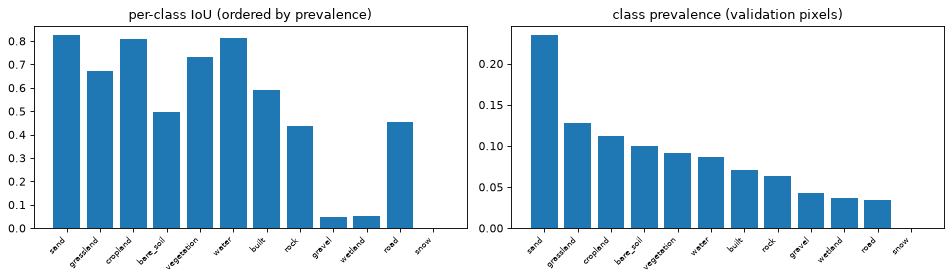

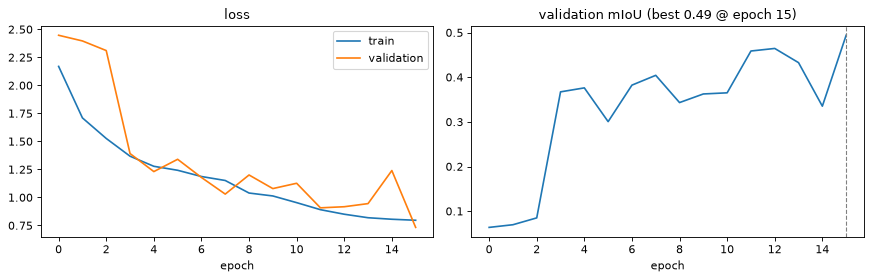

In [9]:
validation_loss, accuracy, mean_iou, per_class_iou = evaluate(val_images, val_labels)
test_loss, test_accuracy, test_iou, _ = evaluate(test_images, test_labels)
print(f"validation pixel accuracy {accuracy:.3f} | mean IoU {mean_iou:.3f}")
print(f"test       pixel accuracy {test_accuracy:.3f} | mean IoU {test_iou:.3f}   <- reported once")
classes_present = list(range(1, len(SEGMENTATION_CLASSES)))
print(
    "per-class IoU:",
    [(SEGMENTATION_CLASSES[class_id], round(value, 3)) for class_id, value in zip(classes_present, per_class_iou)],
)

# Trivial baseline: label every valid pixel with the most frequent training
# class. Its pixel accuracy looks decent while its mIoU is tiny, which is
# exactly why accuracy alone is misleading for segmentation.
train_valid = train_labels[train_labels > 0]
class_counts = np.bincount(train_valid.numpy(), minlength=len(SEGMENTATION_CLASSES))
majority_class = int(class_counts[1:].argmax() + 1)
valid = val_labels > 0
baseline_accuracy = (val_labels[valid] == majority_class).float().mean().item()
classes_present_count = sum(int((val_labels == c).sum()) > 0 for c in range(1, len(SEGMENTATION_CLASSES)))
baseline_miou = baseline_accuracy / classes_present_count
print(f"most-frequent-class baseline: pixel accuracy {baseline_accuracy:.3f} | "
      f"mIoU {baseline_miou:.3f} (always '{SEGMENTATION_CLASSES[majority_class]}')")

# Per-class IoU against class prevalence: rare classes are hard, and because
# mIoU weights every class equally, a few rare classes dominate the mean.
class_names = [SEGMENTATION_CLASSES[c] for c in range(1, len(SEGMENTATION_CLASSES))]
valid_total = max(int((val_labels > 0).sum()), 1)
frequencies = [int((val_labels == c).sum()) / valid_total for c in range(1, len(SEGMENTATION_CLASSES))]
order = np.argsort(frequencies)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), dpi=80)
axes[0].bar(range(len(class_names)), [per_class_iou[i] for i in order])
axes[0].set_xticks(range(len(class_names)), [class_names[i] for i in order], rotation=45, ha="right", fontsize=7)
axes[0].set_title("per-class IoU (ordered by prevalence)")
axes[1].bar(range(len(class_names)), [frequencies[i] for i in order])
axes[1].set_xticks(range(len(class_names)), [class_names[i] for i in order], rotation=45, ha="right", fontsize=7)
axes[1].set_title("class prevalence (validation pixels)")
plt.tight_layout()
plt.show()

# Training curves: the training and validation losses fall together (and the
# validation mIoU rises) before flattening. If the validation loss turned back
# up while the training loss kept falling, the model would be overfitting.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80)
epochs = [row[0] for row in history]
axes[0].plot(epochs, [row[1] for row in history], label="train")
axes[0].plot(epochs, [row[2] for row in history], label="validation")
axes[0].set_title("loss")
axes[0].set_xlabel("epoch"); axes[0].legend()
best_epoch = epochs[int(np.argmax([row[4] for row in history]))]
axes[1].plot(epochs, [row[4] for row in history])
axes[1].axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
axes[1].set_title(f"validation mIoU (best {max(row[4] for row in history):.2f} @ epoch {best_epoch})")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()


**Figure read-out.** Left: per-class IoU ordered by prevalence - the rare classes (`snow`, `gravel`, `wetland`) score near zero. Right: train/validation loss and validation mIoU; both losses fall together and mIoU rises then flattens.

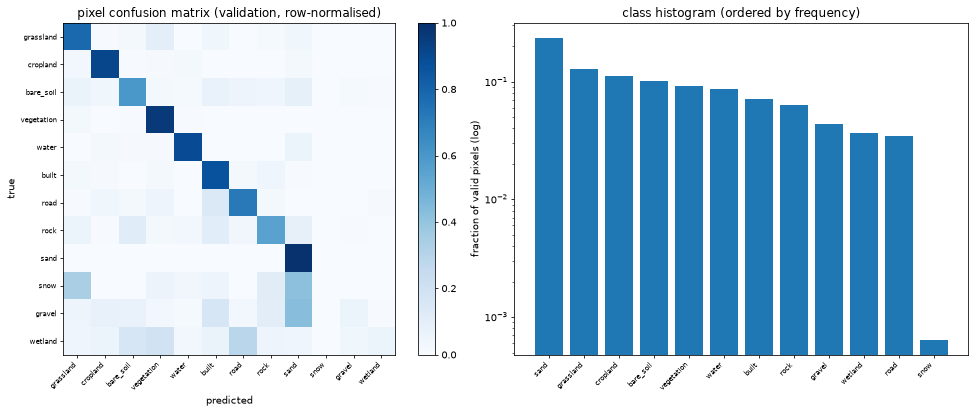

In [10]:
# Pixel-level **confusion matrix** on the validation scenes (valid pixels only,
# class 0 excluded). Rows are the true class, columns the predicted class, and
# each row is normalised to 1. A bright off-diagonal cell is a *systematic*
# confusion (e.g. grassland predicted as cropland), which the per-class IoU
# alone does not show. The histogram beside it gives the class frequencies, so
# rare classes (whose rows are noisy) can be told apart from common ones.
model.eval()
with torch.no_grad():
    val_predictions = model(val_images.to(DEVICE)).argmax(1).cpu()

n_seg = len(SEGMENTATION_CLASSES)
pixel_confusion = np.zeros((n_seg, n_seg), dtype=np.int64)
valid = val_labels > 0
np.add.at(pixel_confusion, (val_labels[valid].numpy(), val_predictions[valid].numpy()), 1)
pixel_confusion = pixel_confusion[1:, 1:]          # drop class 0 (unlabeled)
class_labels = [SEGMENTATION_CLASSES[c] for c in range(1, n_seg)]
row_normalised = pixel_confusion / np.maximum(pixel_confusion.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=70)
image = axes[0].imshow(row_normalised, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(class_labels)), class_labels, rotation=45, ha="right", fontsize=7)
axes[0].set_yticks(range(len(class_labels)), class_labels, fontsize=7)
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
axes[0].set_title("pixel confusion matrix (validation, row-normalised)")
fig.colorbar(image, ax=axes[0], fraction=0.046)

pixel_counts = pixel_confusion.sum(axis=1)
order = np.argsort(pixel_counts)[::-1]
axes[1].bar(range(len(class_labels)), pixel_counts[order] / pixel_counts.sum())
axes[1].set_xticks(range(len(class_labels)), [class_labels[i] for i in order],
                   rotation=45, ha="right", fontsize=7)
axes[1].set_yscale("log")
axes[1].set_ylabel("fraction of valid pixels (log)")
axes[1].set_title("class histogram (ordered by frequency)")
plt.tight_layout()
plt.show()


**Figure read-out.** Left: pixel-level confusion matrix over the validation scenes (rows true, columns predicted, row-normalised). Bright off-diagonal cells expose systematic confusions (e.g. `grassland`/`cropland`, `rock`/`gravel`), which the scalar mIoU hides. Right: the class histogram (log scale) - the rare classes at the bottom are the ones whose rows are statistically noisy and whose low IoU drags mIoU down the most.

## Class imbalance and the loss

The prevalence plot above explains the low per-class IoU of rare classes: with
plain cross-entropy and a dominant class, the loss barely notices them. A
common remedy is a **class-weighted** loss, where each class is scaled by
inverse frequency (here the square root, to avoid over-correcting). We train
both variants on the same short schedule and compare per-class IoU.

With $n_c$ the number of labelled training pixels of class $c$ and $N=\sum_c n_c$, the weights are $w_c\propto\sqrt{N/n_c}$, rescaled so that their mean over the classes present is 1 (classes absent from the training set keep $w_c=1$), and the loss becomes

$$\mathcal{L}_w=-\frac{\sum_{i\in\Omega}w_{y_i}\,\log \mathrm{softmax}(z_i)_{y_i}}{\sum_{i\in\Omega}w_{y_i}}.$$

The denominator is the sum of the weights of the pixels (this is how PyTorch normalises a weighted cross-entropy), not $|\Omega|$. With all $w_c=1$ it reduces to the plain loss $\mathcal L$ above.

plain CE mIoU 0.343 | class-weighted CE mIoU 0.451
per-class IoU (plain -> weighted), rarest first:
  snow       0.000 -> 0.000
  road       0.001 -> 0.384
  wetland    0.037 -> 0.100
  gravel     0.000 -> 0.096
  water      0.632 -> 0.698


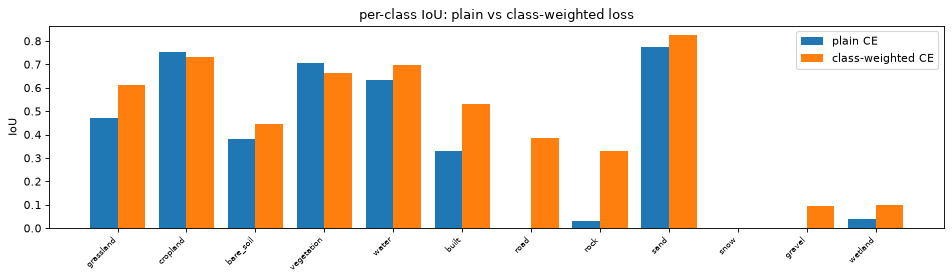

In [11]:
train_valid = train_labels[train_labels > 0]
class_frequency = np.bincount(train_valid.numpy(), minlength=len(SEGMENTATION_CLASSES)).astype(float)
present = class_frequency > 0
class_weights = np.ones(len(SEGMENTATION_CLASSES), dtype=np.float32)
class_weights[present] = (class_frequency[present].sum() / class_frequency[present]) ** 0.5
class_weights[present] /= class_weights[present].mean()
weight_tensor = torch.tensor(class_weights, device=DEVICE)


def train_segmentation(weights, epochs=8, seed=0):
    """Train a fresh U-Net with optional class weights; return val predictions."""
    torch.manual_seed(seed)
    candidate = SmallUNet(len(SEGMENTATION_CLASSES)).to(DEVICE)
    candidate_optimizer = torch.optim.AdamW(candidate.parameters(), lr=2e-3)
    for _ in range(epochs):
        candidate.train()
        permutation = torch.randperm(len(train_images_device), device=DEVICE)
        for start in range(0, len(train_images_device), BATCH_SIZE):
            batch_indices = permutation[start : start + BATCH_SIZE]
            candidate_optimizer.zero_grad()
            loss = F.cross_entropy(
                candidate(train_images_device[batch_indices]),
                train_labels_device[batch_indices], weight=weights, ignore_index=0)
            loss.backward()
            candidate_optimizer.step()
    candidate.eval()
    with torch.no_grad():
        return candidate(val_images.to(DEVICE)).argmax(1).cpu()


def per_class_iou(predictions):
    """Mean IoU and the per-class list (aligned with classes 1..12), labelled pixels only."""
    values, mean_values = [], []
    for class_id in range(1, len(SEGMENTATION_CLASSES)):
        target = val_labels == class_id
        predicted = (predictions == class_id) & (val_labels > 0)
        union = (target | predicted).sum().item()
        iou = (target & predicted).sum().item() / union if union else 0.0
        values.append(iou)
        if union:
            mean_values.append(iou)
    return float(np.mean(mean_values)), values


plain_predictions = train_segmentation(None)
weighted_predictions = train_segmentation(weight_tensor)
plain_miou, plain_per_class = per_class_iou(plain_predictions)
weighted_miou, weighted_per_class = per_class_iou(weighted_predictions)
print(f"plain CE mIoU {plain_miou:.3f} | class-weighted CE mIoU {weighted_miou:.3f}")
print("per-class IoU (plain -> weighted), rarest first:")
for index in np.argsort(class_frequency[1:])[:5]:
    print(f"  {class_names[index]:10s} {plain_per_class[index]:.3f} -> {weighted_per_class[index]:.3f}")


fig, ax = plt.subplots(figsize=(12, 3.6), dpi=80)
positions = np.arange(len(class_names))
ax.bar(positions - 0.2, plain_per_class, width=0.4, label="plain CE")
ax.bar(positions + 0.2, weighted_per_class, width=0.4, label="class-weighted CE")
ax.set_xticks(positions, class_names, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("IoU")
ax.set_title("per-class IoU: plain vs class-weighted loss")
ax.legend()
plt.tight_layout()
plt.show()


**Figure read-out.** Per-class IoU for plain vs class-weighted cross-entropy on the same schedule: weighting lifts the rare classes (`gravel`, `wetland`, `road`) and raises mIoU.

## Class colour legend

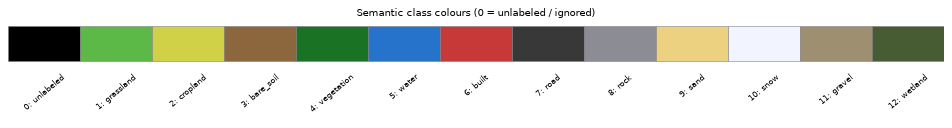

In [12]:
from mplsyn.segmentation import CLASS_COLORS

fig, ax = plt.subplots(figsize=(12, 1.7), dpi=80)
for class_id, class_name in enumerate(SEGMENTATION_CLASSES):
    color = (0.0, 0.0, 0.0) if class_id == 0 else CLASS_COLORS[class_name]
    ax.add_patch(plt.Rectangle((class_id, 0), 1, 1, facecolor=color, edgecolor="grey", linewidth=0.5))
    ax.text(class_id + 0.5, -0.35, f"{class_id}: {class_name}", ha="center", va="top", rotation=40, fontsize=7)
ax.set_xlim(0, len(SEGMENTATION_CLASSES))
ax.set_ylim(-1.7, 1.1)
ax.axis("off")
ax.set_title("Semantic class colours (0 = unlabeled / ignored)", fontsize=9)
plt.tight_layout()
plt.show()


**Figure read-out.** The class-colour legend used by every mask figure: black is the ignored class 0, and each other colour is a land-cover class (`CLASS_COLORS`).

## Prediction grids

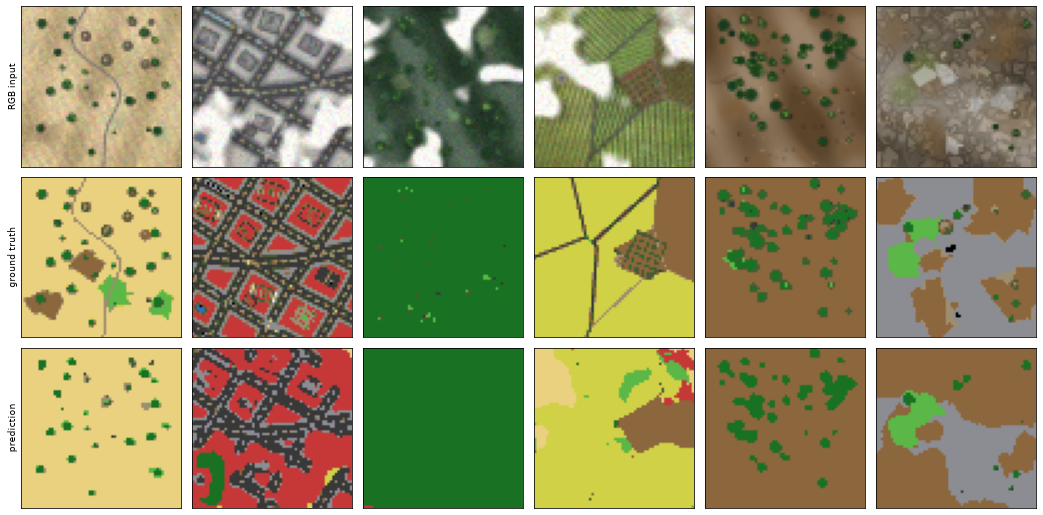

In [13]:
from mplsyn.segmentation import CLASS_COLORS

palette = np.array(
    [[0, 0, 0]] + [[int(255 * c) for c in CLASS_COLORS[name]] for name in SEGMENTATION_CLASSES[1:]],
    dtype=np.uint8,
)
model.eval()
with torch.no_grad():
    predictions = model(val_images[:6].to(DEVICE)).argmax(1).cpu()

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5), dpi=70)
for sample_idx in range(6):
    axes[0, sample_idx].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[1, sample_idx].imshow(palette[val_labels[sample_idx].numpy()])
    axes[2, sample_idx].imshow(palette[predictions[sample_idx].numpy()])
for row, title in enumerate(["RGB input", "ground truth", "prediction"]):
    axes[row, 0].set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


**Figure read-out.** RGB input / ground truth / prediction for six scenes. The U-Net recovers the large classes but blurs thin structures (roads, small water) and areas under cloud.

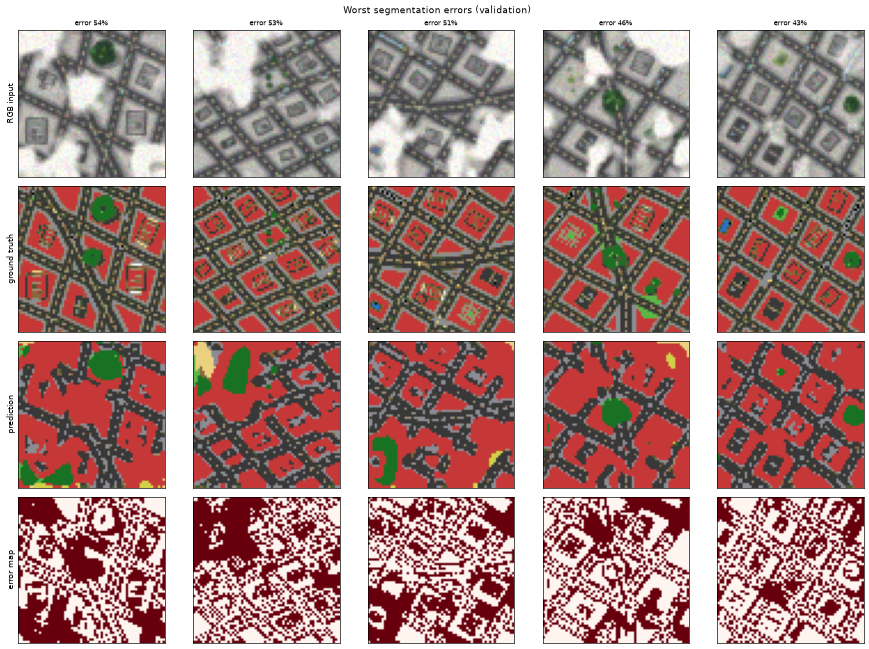

In [14]:
# Failure gallery: the five validation scenes with the largest pixel-error
# fraction, with an explicit error map (red = misclassified, valid pixels only).
model.eval()
with torch.no_grad():
    val_predictions = model(val_images.to(DEVICE)).argmax(1).cpu()
error_fraction = []
for sample_idx in range(len(val_images)):
    valid = val_labels[sample_idx] > 0
    error_fraction.append(float(((val_predictions[sample_idx] != val_labels[sample_idx]) & valid).float().mean()))
worst = np.argsort(error_fraction)[::-1][:5]

fig, axes = plt.subplots(4, 5, figsize=(15, 11), dpi=60)
for col, sample_idx in enumerate(worst):
    axes[0, col].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[0, col].set_title(f"error {error_fraction[sample_idx]:.0%}", fontsize=8)
    axes[1, col].imshow(palette[val_labels[sample_idx].numpy()])
    axes[2, col].imshow(palette[val_predictions[sample_idx].numpy()])
    error_map = (val_predictions[sample_idx] != val_labels[sample_idx]).numpy() & (val_labels[sample_idx].numpy() > 0)
    axes[3, col].imshow(error_map, cmap="Reds", vmin=0, vmax=1)
for ax, title in zip(axes[:, 0], ["RGB input", "ground truth", "prediction", "error map"]):
    ax.set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Worst segmentation errors (validation)", fontsize=11)
plt.tight_layout()
plt.show()


**Figure read-out.** Worst-validation scenes with an error map (red = misclassified valid pixels). Clouded scenes dominate, because the ground is partly hidden.

This notebook segments **64x64** scenes with light sensor noise and ~40 % cloud cover
(mostly opaque, about a quarter semi-transparent), and the semantic mask is evaluated even under clouds that partly
hide the ground. Perfect per-pixel accuracy would require seeing through clouds.

### Interpreting these numbers

The scores above are measured on **deliberately hard** imagery, not a clean
benchmark, and that is the point of a synthetic dataset:

- **High accuracy on clean images can mislead.** A segmenter can look
  near-perfect on pristine renders and still fail on the first cloudy or blurry
  acquisition; a slightly lower number on degraded data is the more honest one.
- **The degradation bounds what any model can recover.** Under cloud cover the
  ground is physically hidden, and structures only a few pixels wide (a thin
  track, a small pool) cannot be segmented reliably. No architecture beats that
  ceiling; it is a property of the data, not a bug.
- **Some errors are irreducible.** A boundary between two materials is a
  judgement call even for a human annotator.
- **Report per-class IoU, not just accuracy.** The mean IoU exposes the rare,
  hard classes that a single pixel-accuracy number hides.

The takeaway is not "the model is bad", but "these metrics quantify **robustness
under realistic conditions**"; improving them means better resolution or priors.
